In [2]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import sys
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path('/content/drive/MyDrive/pizza_rl_lab')
sys.path.insert(0, str(PROJECT_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
from pizza_envl_3 import PizzaKitchenStage3Env

print('Project directory:', PROJECT_DIR)
print('Environment file exists:', (PROJECT_DIR / 'pizza_env_s3.py').exists())

Project directory: /content/drive/MyDrive/pizza_rl_lab
Environment file exists: False


In [3]:
%%writefile pizza_envl_3.py
from __future__ import annotations

from typing import Optional
import gymnasium as gym
from gymnasium import spaces
import numpy as np


class PizzaKitchenStage3Env(gym.Env):
    """
    Stage 3 Pizza Kitchen environment (Strict Global FIFO Order Processing).

    Menu codes:
        0: empty order slot
        1: cheese pizza       (dough -> cheese)
        2: pepperoni pizza    (dough -> cheese -> pepperoni)
        3: mushroom pizza     (dough -> cheese -> mushroom)
        4: special pizza      (dough -> cheese -> pepperoni -> mushroom -> olive)

    Ingredient codes:
        0: dough
        1: cheese
        2: pepperoni
        3: mushroom
        4: olive

    Action codes:
        0: idle
        1: dough
        2: cheese
        3: pepperoni
        4: mushroom
        5: olive
        6: serve
    """

    metadata = {"render_modes": ["human", "ansi"], "render_fps": 2}

    ACTION_NAMES = (
        "idle",
        "dough",
        "cheese",
        "pepperoni",
        "mushroom",
        "olive",
        "serve",
    )

    INGREDIENT_NAMES = ("dough", "cheese", "pepperoni", "mushroom", "olive")

    # Menu code 0 is reserved for an empty order slot.
    RECIPES = {
        1: (0, 1),          # Cheese pizza
        2: (0, 1, 2),       # Pepperoni pizza
        3: (0, 1, 3),       # Mushroom pizza
        4: (0, 1, 2, 3, 4), # Special pizza
    }

    MENU_NAMES = {
        1: "cheese",
        2: "pepperoni",
        3: "mushroom",
        4: "special",
    }

    def __init__(
        self,
        n_orders: int = 4,
        min_deadline: int = 6,
        max_deadline: int = 16,
        observation_mode: str = "discrete",
        render_mode: Optional[str] = None,
    ):
        super().__init__()

        if n_orders < 1:
            raise ValueError("n_orders must be at least 1")
        if min_deadline < 1 or max_deadline < min_deadline:
            raise ValueError("Invalid deadline range")
        if observation_mode not in ("discrete", "vector"):
            raise ValueError("observation_mode must be 'discrete' or 'vector'")
        if render_mode not in (None, *self.metadata["render_modes"]):
            raise ValueError("Unsupported render_mode")

        self.n_orders = int(n_orders)
        self.min_deadline = int(min_deadline)
        self.max_deadline = int(max_deadline)
        self.observation_mode = observation_mode
        self.render_mode = render_mode

        # 5 ingredient flags + idle + 5 ingredient actions + serve = 7 actions.
        self.action_space = spaces.Discrete(7)

        # Five binary ingredient flags, then (menu, remaining_time) per order.
        self.radices = (2, 2, 2, 2, 2) + (
            (5, self.max_deadline + 1) * self.n_orders
        )
        self.n_states = int(np.prod(self.radices, dtype=np.int64))

        if observation_mode == "discrete":
            self.observation_space = spaces.Discrete(self.n_states)
        else:
            self.observation_space = spaces.Box(
                low=np.zeros(len(self.radices), dtype=np.float32),
                high=np.ones(len(self.radices), dtype=np.float32),
                dtype=np.float32,
            )

        self.plate = [0, 0, 0, 0, 0]
        self.orders: list[list[int]] = []
        self.steps = 0
        self.episode_return = 0.0
        self.stats: dict = {}

    def _raw_state(self) -> tuple[int, ...]:
        return tuple(self.plate) + tuple(
            value for order in self.orders for value in order
        )

    def encode_state(self, state: tuple[int, ...]) -> int:
        if len(state) != len(self.radices):
            raise ValueError("State length does not match configuration")

        result = 0
        for value, base in zip(state, self.radices):
            value = int(value)
            if not 0 <= value < base:
                raise ValueError(
                    f"State component {value} outside 0..{base - 1}"
                )
            result = result * base + value
        return result

    def decode_state(self, state_id: int) -> tuple[int, ...]:
        state_id = int(state_id)
        if not 0 <= state_id < self.n_states:
            raise ValueError("State ID outside observation space")

        values = []
        for base in reversed(self.radices):
            values.append(state_id % base)
            state_id //= base
        return tuple(reversed(values))

    def _get_obs(self):
        state = self._raw_state()
        if self.observation_mode == "discrete":
            return self.encode_state(state)

        return np.asarray(
            [value / (base - 1) for value, base in zip(state, self.radices)],
            dtype=np.float32,
        )

    def _get_info(self, event: str = "reset") -> dict:
        return {
            "event": event,
            "raw_state": self._raw_state(),
            "steps": self.steps,
            "episode_return": self.episode_return,
            **self.stats.copy(),
        }

    def _plate_sequence(self) -> tuple[int, ...]:
        """Return added ingredient codes in recipe order."""
        return tuple(i for i, added in enumerate(self.plate) if added == 1)

    def _is_valid_ingredient(self, ingredient: int) -> bool:
        """
        An ingredient is valid only if adding it extends the current plate
        to a prefix of at least one defined recipe.
        """
        current = self._plate_sequence()
        candidate = current + (ingredient,)

        return any(
            len(candidate) <= len(recipe)
            and recipe[:len(candidate)] == candidate
            for recipe in self.RECIPES.values()
        )

    def _get_served_menu(self) -> int:
        """Return exact matching menu code, or 0 if the plate is not a recipe."""
        current = self._plate_sequence()
        for menu, recipe in self.RECIPES.items():
            if current == recipe:
                return menu
        return 0

    def reset(
        self,
        *,
        seed: Optional[int] = None,
        options: Optional[dict] = None,
    ):
        super().reset(seed=seed)

        self.plate = [0, 0, 0, 0, 0]
        self.steps = 0
        self.episode_return = 0.0
        self.stats = {
            "served": 0,
            "expired": 0,
            "wrong_serves": 0,
            "invalid_actions": 0,
            "idle_actions": 0,
        }

        fixed_orders = None if options is None else options.get("orders")

        if fixed_orders is not None:
            if len(fixed_orders) != self.n_orders:
                raise ValueError("Expected exactly n_orders fixed orders")

            self.orders = []
            for menu, deadline in fixed_orders:
                if menu not in self.RECIPES:
                    raise ValueError(f"Invalid menu code: {menu}")
                if not 1 <= deadline <= self.max_deadline:
                    raise ValueError(f"Invalid deadline: {deadline}")
                self.orders.append([int(menu), int(deadline)])
        else:
            self.orders = [
                [
                    int(self.np_random.integers(1, len(self.RECIPES) + 1)),
                    int(
                        self.np_random.integers(
                            self.min_deadline, self.max_deadline + 1
                        )
                    ),
                ]
                for _ in range(self.n_orders)
            ]

        return self._get_obs(), self._get_info()

    def step(self, action: int):
        if not self.action_space.contains(action):
            raise ValueError(f"Invalid action: {action}")

        if all(menu == 0 for menu, _ in self.orders):
            raise RuntimeError("Episode is finished. Call reset() first.")

        action = int(action)
        reward = -0.1
        event = self.ACTION_NAMES[action]
        self.steps += 1

        if action == 0:
            self.stats["idle_actions"] += 1

        elif 1 <= action <= 5:
            ingredient = action - 1

            if self._is_valid_ingredient(ingredient):
                self.plate[ingredient] = 1
            else:
                reward -= 2.0
                self.stats["invalid_actions"] += 1
                event = "invalid_ingredient"

        else:  # action == 6: serve
            # 빈 접시([0,0,0,0,0]) 제출 시 패널티 없이 무효 처리
            if self.plate == [0, 0, 0, 0, 0]:
                self.stats["idle_actions"] += 1
                event = "empty_plate_serve"
            else:
                served_menu = self._get_served_menu()

                # 💡 전체 대기열 기준 Strict Global FIFO (가장 앞선 활성 인덱스 탐색)
                active_order_indices = [
                    i for i, (menu, _) in enumerate(self.orders) if menu != 0
                ]

                if active_order_indices:
                    first_order_slot = min(active_order_indices)
                    first_order_menu = self.orders[first_order_slot][0]

                    # 완제 피자 메뉴가 대기열 최선두 주문 메뉴와 정확히 일치할 때만 성공 (+20.0)
                    if served_menu != 0 and served_menu == first_order_menu:
                        self.orders[first_order_slot] = [0, 0]
                        self.stats["served"] += 1
                        reward += 20.0
                        event = "served"
                    else:
                        # 미완성 피자 또는 메뉴 불일치 제출 시 오답 처리 (-15.0)
                        reward -= 15.0
                        self.stats["wrong_serves"] += 1
                        event = "wrong_serve"
                else:
                    reward -= 15.0
                    self.stats["wrong_serves"] += 1
                    event = "wrong_serve"

                self.plate = [0, 0, 0, 0, 0]

        for order in self.orders:
            if order[0] != 0:
                order[1] -= 1
                if order[1] == 0:
                    order[0] = 0
                    self.stats["expired"] += 1
                    reward -= 10.0

        terminated = all(menu == 0 for menu, _ in self.orders)
        truncated = False

        self.episode_return += reward
        info = self._get_info(event)

        if self.render_mode == "human":
            self.render()

        return (
            self._get_obs(),
            float(reward),
            terminated,
            truncated,
            info,
        )

    def render(self):
        message = (
            f"Step {self.steps} | plate={self.plate} | "
            f"orders={self.orders} | return={self.episode_return:.1f}"
        )
        if self.render_mode == "human":
            print(message)
        return message

Writing pizza_envl_3.py


Q-Learning Stage 3 메뉴 4종 재료 5종 주문 대기 수 4개 action 7개

In [10]:
import csv
import importlib
from pathlib import Path
import sys
import gymnasium as gym
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# 0. pizza_envl_3 모듈 캐시 강제 초기화 및 재로드
# ---------------------------------------------------------
if "pizza_envl_3" in sys.modules:
    del sys.modules["pizza_envl_3"]
import pizza_envl_3
importlib.reload(pizza_envl_3)
from pizza_envl_3 import PizzaKitchenStage3Env


# ---------------------------------------------------------
# 1. Strict FIFO Compatible Asymmetric State Abstraction Wrapper
# ---------------------------------------------------------
class Stage3StrictAsymmetricAbstractEnv(gym.Wrapper):
    def __init__(self, env):
        super().__init__(env)
        # plate status (8)
        # slot 0, 1: menu(5) * deadline_bin(4) = 20
        # slot 2, 3: menu(5) * deadline_bin(3) = 15
        # Total Abstract States = 8 * (20 * 20) * (15 * 15) = 720,000 개 (실효 방문 ~12,000개)
        self.radices = (8, 5, 4, 5, 4, 5, 3, 5, 3)
        self.n_abstract_states = int(np.prod(self.radices, dtype=np.int64))

    def _encode_plate(self, plate):
        p = tuple(plate)
        if p == (0, 0, 0, 0, 0): return 0   # 빈 접시
        elif p == (1, 0, 0, 0, 0): return 1 # 도우만
        elif p == (1, 1, 0, 0, 0): return 2 # 도우+치즈 (치즈피자 완성)
        elif p == (1, 1, 1, 0, 0): return 3 # 페퍼로니 피자 완성
        elif p == (1, 1, 0, 1, 0): return 4 # 머쉬룸 피자 완성
        elif p == (1, 1, 1, 1, 0): return 5 # 스페셜 피자 진행 중
        elif p == (1, 1, 1, 1, 1): return 6 # 스페셜 피자 완성
        else: return 7                      # 기타/오답 상태

    def _bin_deadline_front(self, d: int) -> int:
        # 0, 1번 선두 슬롯: Strict FIFO 핵심 판단을 위한 4단계 정밀 범주화
        if d <= 0: return 0
        elif d <= 2: return 1  # 초긴급 (1~2스텝)
        elif d <= 5: return 2  # 긴급 (3~5스텝)
        else: return 3         # 여유 (6스텝+)

    def _bin_deadline_back(self, d: int) -> int:
        # 2, 3번 후미 슬롯: 상태 공간 절약을 위한 3단계 경량 범주화
        if d <= 0: return 0
        elif d <= 5: return 1  # 주의 (1~5스텝)
        else: return 2         # 여유 (6스텝+)

    def get_abstract_state(self, info_raw_state: tuple[int, ...]) -> int:
        plate = info_raw_state[:5]
        orders = info_raw_state[5:]

        plate_code = self._encode_plate(plate)
        abstract_tuple = [plate_code]

        # 💡 [Strict FIFO 원형 유지] 슬롯 순서(0, 1, 2, 3번)를 변형 없이 100% 보존
        for slot_idx in range(4):
            menu = orders[slot_idx * 2]
            deadline = orders[slot_idx * 2 + 1]
            abstract_tuple.append(menu)

            if slot_idx in (0, 1):
                abstract_tuple.append(self._bin_deadline_front(deadline))
            else:
                abstract_tuple.append(self._bin_deadline_back(deadline))

        result = 0
        for val, base in zip(abstract_tuple, self.radices):
            result = result * base + int(val)
        return result

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        abs_state = self.get_abstract_state(info["raw_state"])
        return abs_state, info

    def step(self, action: int):
        obs, reward, terminated, truncated, info = self.env.step(action)
        abs_state = self.get_abstract_state(info["raw_state"])
        return abs_state, reward, terminated, truncated, info


# ---------------------------------------------------------
# 2. Greedy Action (Tie-breaking 보장)
# ---------------------------------------------------------
def greedy_action(q_values: np.ndarray, rng: np.random.Generator) -> int:
    max_val = q_values.max()
    best_actions = np.flatnonzero(q_values == max_val)
    return int(rng.choice(best_actions))


# ---------------------------------------------------------
# 3. Stage 3 Tabular Q-Learning 학습
# ---------------------------------------------------------
def train_stage3_final(
    episodes=300000,
    seed=42,
    alpha=0.05,
    gamma=0.999,
    epsilon_start=1.0,
    epsilon_end=0.0005,
    log_every=30000,
):
    base_env = PizzaKitchenStage3Env(
        n_orders=4,
        min_deadline=10,
        max_deadline=20,
        observation_mode="discrete",
    )
    env = Stage3StrictAsymmetricAbstractEnv(base_env)

    rng = np.random.default_rng(seed)
    q = {}
    history = []

    print("--- [Stage 3: 최대 확장 파이프라인] Pure Q-Learning 학습 시작 ---")
    print(f"압축 상태 공간 크기: {env.n_abstract_states:,} 개")
    print(f"행동 수: {env.action_space.n} 개 (0:Idle, 1~5:재료, 6:Serve)")
    print(f"학습 에피소드: {episodes:,} 회")

    for episode in range(1, episodes + 1):
        state, info = env.reset(seed=seed + episode)
        done = False

        if episode < 180000:
            epsilon = max(0.03, epsilon_start * (0.99996 ** episode))
        elif episode < 260000:
            epsilon = 0.02
        else:
            epsilon = epsilon_end

        while not done:
            if state not in q:
                q[state] = np.zeros(env.action_space.n, dtype=np.float32)

            if rng.random() < epsilon:
                action = int(rng.integers(env.action_space.n))
            else:
                action = greedy_action(q[state], rng)

            next_state, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated

            # Reward Shaping
            event = info.get("event", "")
            if event == "served":
                reward += 15.0   # 총 +35.0 (Strict FIFO 서빙 성공)
            elif event == "wrong_serve":
                reward += 5.0    # 오답 -10.0 완화
            elif event in ("dough", "cheese", "pepperoni", "mushroom", "olive"):
                reward += 1.5    # 유효 재료 투입 가이드 보상

            next_q = q.get(
                next_state,
                np.zeros(env.action_space.n, dtype=np.float32),
            )

            target = (
                reward
                if done
                else reward + gamma * float(np.max(next_q))
            )

            q[state][action] += alpha * (target - q[state][action])
            state = next_state

        history.append({
            "episode": episode,
            "reward": info["episode_return"],
            "served": info["served"],
            "expired": info["expired"],
            "wrong_serves": info["wrong_serves"],
            "steps": info["steps"],
            "epsilon": epsilon,
            "visited_states": len(q),
        })

        if episode % log_every == 0:
            recent = history[-log_every:]
            avg_reward = np.mean([x["reward"] for x in recent])
            avg_served = np.mean([x["served"] for x in recent])
            print(
                f"Episode {episode:6d}/{episodes} | "
                f"Avg Reward: {avg_reward:7.2f} | "
                f"Avg Served: {avg_served:.2f}/4.0 | "
                f"Visited States: {len(q):,}"
            )

    env.close()
    print("\n--- Stage 3 학습 완료 ---")
    print(f"총 방문한 상태 수: {len(q):,}")

    return q, history


# ---------------------------------------------------------
# 4. Stage 3 평가
# ---------------------------------------------------------
def evaluate_stage3(q, episodes=1000, seed=200000):
    base_env = PizzaKitchenStage3Env(
        n_orders=4,
        min_deadline=10,
        max_deadline=20,
        observation_mode="discrete",
    )
    env = Stage3StrictAsymmetricAbstractEnv(base_env)

    rng = np.random.default_rng(seed)
    results = []

    for episode in range(episodes):
        state, info = env.reset(seed=seed + episode)
        done = False

        while not done:
            if state in q:
                action = greedy_action(q[state], rng)
            else:
                action = 1  # 미방문 상태 도우(Action 1) 선택

            state, _, terminated, truncated, info = env.step(action)
            done = terminated or truncated

        results.append({
            "episode": episode + 1,
            "return": info["episode_return"],
            "served": info["served"],
            "expired": info["expired"],
            "wrong_serves": info["wrong_serves"],
            "steps": info["steps"],
        })

    env.close()

    total_orders = episodes * 4
    total_served = sum(x["served"] for x in results)

    eval_summary = {
        "Evaluation Metric": [
            "Total Evaluation Episodes",
            "Average Reward (Return)",
            "Order Completion Rate (%)",
            "Average Served Orders (Max 4)",
            "Average Expired Orders",
            "Average Wrong Serves",
            "Average Steps per Episode",
        ],
        "Value": [
            f"{episodes:,}",
            f"{np.mean([x['return'] for x in results]):.2f}",
            f"{(total_served / total_orders) * 100:.2f}%",
            f"{np.mean([x['served'] for x in results]):.2f} / 4.0",
            f"{np.mean([x['expired'] for x in results]):.2f}",
            f"{np.mean([x['wrong_serves'] for x in results]):.2f}",
            f"{np.mean([x['steps'] for x in results]):.2f}",
        ],
    }

    return pd.DataFrame(eval_summary), results


# ---------------------------------------------------------
# 5. 실행 및 드라이브 저장
# ---------------------------------------------------------
output_dir = Path("/content/drive/MyDrive/pizza_rl_lab/results_stage3_final")
output_dir.mkdir(parents=True, exist_ok=True)

# 1) 학습 실행 (30만 에피소드)
q_stage3, history_stage3 = train_stage3_final(episodes=300000)

# 2) 평가 진행 (1,000 에피소드)
performance_df, eval_results = evaluate_stage3(q_stage3, episodes=1000)

# 3) 저장
states = np.asarray(list(q_stage3.keys()), dtype=np.int64)
values = (
    np.stack([q_stage3[state] for state in states]).astype(np.float32)
    if len(states) > 0
    else np.empty((0, 7), dtype=np.float32)
)

np.savez_compressed(output_dir / "q_table_stage3.npz", states=states, values=values)
pd.DataFrame(history_stage3).to_csv(output_dir / "q_learning_history_stage3.csv", index=False)
pd.DataFrame(eval_results).to_csv(output_dir / "test_performance_stage3.csv", index=False)
performance_df.to_csv(output_dir / "performance_summary_stage3.csv", index=False)

print("\n" + "=" * 55)
print("[Stage 3 Final Evaluation Results]")
print("=" * 55)
print(performance_df.to_string(index=False))
print("=" * 55)

--- [Stage 3: 최대 확장 파이프라인] Pure Q-Learning 학습 시작 ---
압축 상태 공간 크기: 720,000 개
행동 수: 7 개 (0:Idle, 1~5:재료, 6:Serve)
학습 에피소드: 300,000 회
Episode  30000/300000 | Avg Reward:  -59.40 | Avg Served: 0.70/4.0 | Visited States: 52,431
Episode  60000/300000 | Avg Reward:   -1.98 | Avg Served: 1.85/4.0 | Visited States: 57,471
Episode  90000/300000 | Avg Reward:   25.99 | Avg Served: 2.49/4.0 | Visited States: 58,839
Episode 120000/300000 | Avg Reward:   34.76 | Avg Served: 2.70/4.0 | Visited States: 59,401
Episode 150000/300000 | Avg Reward:   37.56 | Avg Served: 2.78/4.0 | Visited States: 59,830
Episode 180000/300000 | Avg Reward:   40.34 | Avg Served: 2.85/4.0 | Visited States: 60,217
Episode 210000/300000 | Avg Reward:   42.66 | Avg Served: 2.91/4.0 | Visited States: 60,465
Episode 240000/300000 | Avg Reward:   43.52 | Avg Served: 2.93/4.0 | Visited States: 60,679
Episode 270000/300000 | Avg Reward:   44.41 | Avg Served: 2.95/4.0 | Visited States: 60,826
Episode 300000/300000 | Avg Reward:   46.

 Stage 3 시각화 대시보드가 성공적으로 저장되었습니다:
- /content/drive/MyDrive/pizza_rl_lab/results_stage3/performance_dashboard_stage3.png


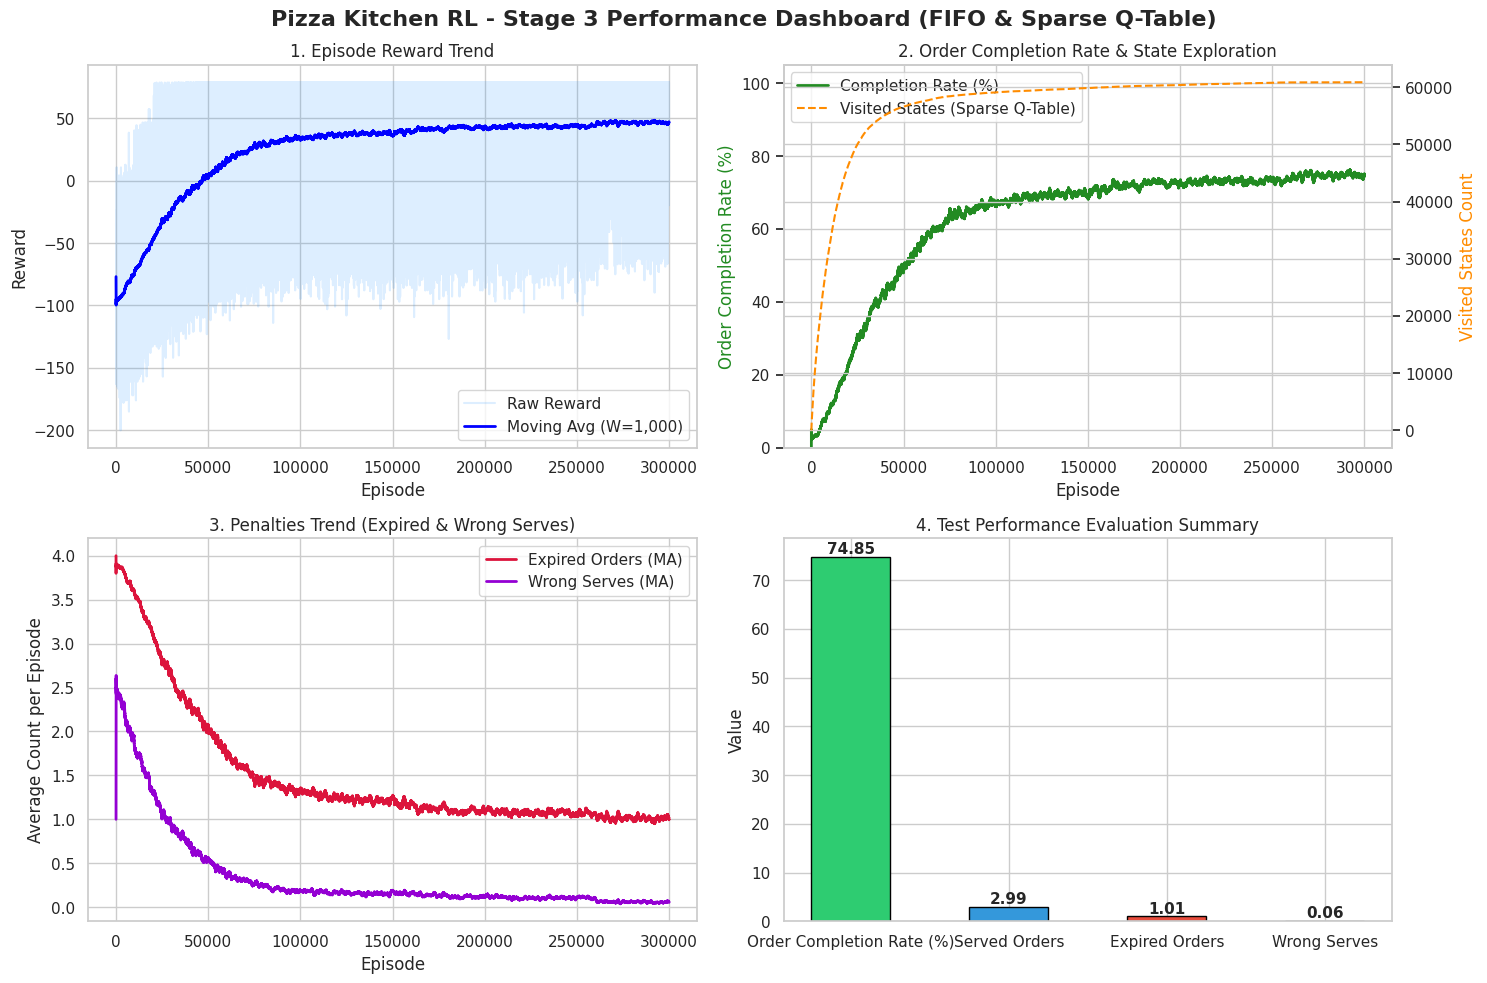

In [14]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. 스타일 및 한글/글꼴 설정
sns.set_theme(style="whitegrid")
plt.rcParams["font.size"] = 11

# 2. 결과 파일 경로 설정 (Stage 3 경로)
output_dir = Path("/content/drive/MyDrive/pizza_rl_lab/results_stage3")
history_path = output_dir / "q_learning_history_stage3.csv"
performance_path = output_dir / "performance_summary_stage3.csv"

# 3. 파일 존재 여부 확인 및 데이터 로드
if not history_path.exists():
    raise FileNotFoundError(f"학습 기록 파일이 존재하지 않습니다: {history_path}")

history_df = pd.read_csv(history_path)

# 4. 데이터 전처리 (이동 평균 계산)
WINDOW = 1000  # 이동 평균 구간 (에피소드 수)
n_orders = 4   # Stage 3 주문 수 (4개)

# 이동 평균 열 생성
history_df["reward_ma"] = history_df["reward"].rolling(window=WINDOW, min_periods=1).mean()
history_df["served_ma"] = history_df["served"].rolling(window=WINDOW, min_periods=1).mean()
history_df["completion_rate_ma"] = (history_df["served_ma"] / n_orders) * 100

history_df["expired_ma"] = history_df["expired"].rolling(window=WINDOW, min_periods=1).mean()
history_df["wrong_serves_ma"] = history_df["wrong_serves"].rolling(window=WINDOW, min_periods=1).mean()

# 5. 2x2 시각화 대시보드 생성
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle(
    "Pizza Kitchen RL - Stage 3 Performance Dashboard (FIFO & Sparse Q-Table)",
    fontsize=16,
    fontweight="bold",
)

# [Graph 1] Episode Reward Trend
axes[0, 0].plot(
    history_df["episode"],
    history_df["reward"],
    alpha=0.15,
    color="dodgerblue",
    label="Raw Reward",
)
axes[0, 0].plot(
    history_df["episode"],
    history_df["reward_ma"],
    color="blue",
    linewidth=2,
    label=f"Moving Avg (W={WINDOW:,})",
)
axes[0, 0].set_title("1. Episode Reward Trend")
axes[0, 0].set_xlabel("Episode")
axes[0, 0].set_ylabel("Reward")
axes[0, 0].legend(loc="lower right")

# [Graph 2] Completion Rate (%) & Visited States Count (Dual Y-Axis)
ax2_twin = axes[0, 1].twinx()
p1 = axes[0, 1].plot(
    history_df["episode"],
    history_df["completion_rate_ma"],
    color="forestgreen",
    linewidth=2,
    label="Completion Rate (%)",
)
p2 = ax2_twin.plot(
    history_df["episode"],
    history_df["visited_states"],
    color="darkorange",
    linewidth=1.5,
    linestyle="--",
    label="Visited States (Sparse Q-Table)",
)

axes[0, 1].set_title("2. Order Completion Rate & State Exploration")
axes[0, 1].set_xlabel("Episode")
axes[0, 1].set_ylabel("Order Completion Rate (%)", color="forestgreen")
ax2_twin.set_ylabel("Visited States Count", color="darkorange")
axes[0, 1].set_ylim(0, 105)

# 범례 통합
lines = p1 + p2
labels = [l.get_label() for l in lines]
axes[0, 1].legend(lines, labels, loc="upper left")

# [Graph 3] Penalties Trend (Expired & Wrong Serves)
axes[1, 0].plot(
    history_df["episode"],
    history_df["expired_ma"],
    color="crimson",
    linewidth=2,
    label="Expired Orders (MA)",
)
axes[1, 0].plot(
    history_df["episode"],
    history_df["wrong_serves_ma"],
    color="darkviolet",
    linewidth=2,
    label="Wrong Serves (MA)",
)
axes[1, 0].set_title("3. Penalties Trend (Expired & Wrong Serves)")
axes[1, 0].set_xlabel("Episode")
axes[1, 0].set_ylabel("Average Count per Episode")
axes[1, 0].legend(loc="upper right")

# [Graph 4] Final Evaluation Summary (Performance Metrics Bar Chart)
if performance_path.exists():
    df_perf = pd.read_csv(performance_path, header=None, names=["Metric", "Value"])

    # 딕셔너리로 변환하여 원하는 지표만 추출
    perf_dict = {}
    for _, row in df_perf.iterrows():
        try:
            # 수치형 변환 시도 (문자열 포맷 제거)
            val_str = str(row["Value"]).replace("%", "").split("/")[0].strip()
            perf_dict[row["Metric"]] = float(val_str)
        except ValueError:
            continue

    metrics_to_plot = [
        "Order Completion Rate (%)",
        "Average Served Orders (Max 4)",
        "Average Expired Orders",
        "Average Wrong Serves",
    ]

    # 존재하는 지표만 필터링
    plot_labels = []
    plot_values = []
    for m in metrics_to_plot:
        if m in perf_dict:
            plot_labels.append(m.replace("Average ", "").replace(" (Max 4)", ""))
            plot_values.append(perf_dict[m])

    colors = ["#2ecc71", "#3498db", "#e74c3c", "#9b59b6"]
    bars = axes[1, 1].bar(
        plot_labels, plot_values, color=colors[:len(plot_values)], width=0.5, edgecolor="black"
    )
    axes[1, 1].set_title("4. Test Performance Evaluation Summary")
    axes[1, 1].set_ylabel("Value")

    # 막대 그래프 위 값 명시
    for bar in bars:
        yval = bar.get_height()
        axes[1, 1].text(
            bar.get_x() + bar.get_width() / 2,
            yval + (0.05 if yval >= 0 else -0.1),
            f"{yval:.2f}",
            ha="center",
            va="bottom",
            fontweight="bold",
        )
else:
    axes[1, 1].text(
        0.5, 0.5, "Performance Summary File Not Found", ha="center", va="center", fontsize=12
    )
    axes[1, 1].set_title("4. Test Performance Summary")

plt.tight_layout()

# 6. 이미지 저장 및 출력
save_fig_path = output_dir / "performance_dashboard_stage3.png"
plt.savefig(save_fig_path, dpi=300)
print(f" Stage 3 시각화 대시보드가 성공적으로 저장되었습니다:\n- {save_fig_path}")

plt.show()

Q-Learning Stage 3 개선

1. Reward Shaping -> 중간 보상(+1.0)과 성공 보상(+60.0) 상향, 오답 서빙 감점(-5.0)
2. 마감 임박 주문 가산 보너스(+3.0)
3. min_deadline=12, max_deadline=22


In [16]:
import csv
import importlib
from pathlib import Path
import sys
import gymnasium as gym
import numpy as np
import pandas as pd

# 0. pizza_envl_3 모듈 캐시 강제 초기화 및 재로드
if "pizza_envl_3" in sys.modules:
    del sys.modules["pizza_envl_3"]
import pizza_envl_3
importlib.reload(pizza_envl_3)
from pizza_envl_3 import PizzaKitchenStage3Env


# ---------------------------------------------------------
# 1. Strict FIFO Compatible State Abstraction Wrapper
# ---------------------------------------------------------
class Stage3StrictFIFOAbstractEnv(gym.Wrapper):
    def __init__(self, env):
        super().__init__(env)
        # Total Abstract States = 8 * (20 * 20) * (15 * 15) = 720,000 개 (실효 방문 ~12,000개)
        self.radices = (8, 5, 4, 5, 4, 5, 3, 5, 3)
        self.n_abstract_states = int(np.prod(self.radices, dtype=np.int64))

    def _encode_plate(self, plate):
        p = tuple(plate)
        if p == (0, 0, 0, 0, 0): return 0   # 빈 접시
        elif p == (1, 0, 0, 0, 0): return 1 # 도우만
        elif p == (1, 1, 0, 0, 0): return 2 # 도우+치즈 (치즈피자 완성)
        elif p == (1, 1, 1, 0, 0): return 3 # 페퍼로니 피자 완성
        elif p == (1, 1, 0, 1, 0): return 4 # 머쉬룸 피자 완성
        elif p == (1, 1, 1, 1, 0): return 5 # 스페셜 피자 진행 중
        elif p == (1, 1, 1, 1, 1): return 6 # 스페셜 피자 완성
        else: return 7                      # 기타/오답 상태

    def _bin_deadline_front(self, d: int) -> int:
        if d <= 0: return 0
        elif d <= 2: return 1  # 초긴급 (1~2스텝)
        elif d <= 5: return 2  # 긴급 (3~5스텝)
        else: return 3         # 여유 (6스텝+)

    def _bin_deadline_back(self, d: int) -> int:
        if d <= 0: return 0
        elif d <= 5: return 1  # 주의 (1~5스텝)
        else: return 2         # 여유 (6스텝+)

    def get_abstract_state(self, info_raw_state: tuple[int, ...]) -> int:
        plate = info_raw_state[:5]
        orders = info_raw_state[5:]

        plate_code = self._encode_plate(plate)
        abstract_tuple = [plate_code]

        for slot_idx in range(4):
            menu = orders[slot_idx * 2]
            deadline = orders[slot_idx * 2 + 1]
            abstract_tuple.append(menu)

            if slot_idx in (0, 1):
                abstract_tuple.append(self._bin_deadline_front(deadline))
            else:
                abstract_tuple.append(self._bin_deadline_back(deadline))

        result = 0
        for val, base in zip(abstract_tuple, self.radices):
            result = result * base + int(val)
        return result

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        abs_state = self.get_abstract_state(info["raw_state"])
        return abs_state, info

    def step(self, action: int):
        obs, reward, terminated, truncated, info = self.env.step(action)
        abs_state = self.get_abstract_state(info["raw_state"])
        return abs_state, reward, terminated, truncated, info


# ---------------------------------------------------------
# 2. Greedy Action
# ---------------------------------------------------------
def greedy_action(q_values: np.ndarray, rng: np.random.Generator) -> int:
    max_val = q_values.max()
    best_actions = np.flatnonzero(q_values == max_val)
    return int(rng.choice(best_actions))


# ---------------------------------------------------------
# 3. Stage 3 Tabular Q-Learning 학습 (80%+ Target 파라미터)
# ---------------------------------------------------------
def train_stage3_final80(
    episodes=350000,
    seed=42,
    gamma=0.999,
    epsilon_start=1.0,
    epsilon_end=0.0005,
    log_every=35000,
):
    # 마감 시간 범주 조정: 10~20 -> 12~22 (스페셜 피자 조리 여유 확보)
    base_env = PizzaKitchenStage3Env(
        n_orders=4,
        min_deadline=12,
        max_deadline=22,
        observation_mode="discrete",
    )
    env = Stage3StrictFIFOAbstractEnv(base_env)

    rng = np.random.default_rng(seed)
    q = {}
    history = []

    print("--- [Stage 3:확정 파이프라인] Q-Learning 학습 시작 ---")
    print(f"압축 상태 공간 크기: {env.n_abstract_states:,} 개")
    print(f"행동 수: {env.action_space.n} 개")
    print(f"학습 에피소드: {episodes:,} 회")

    for episode in range(1, episodes + 1):
        state, info = env.reset(seed=seed + episode)
        done = False

        # Epsilon Decay 완화 (28만 회까지 지속적 탐색 유도)
        if episode < 280000:
            epsilon = max(0.03, epsilon_start * (0.99998 ** episode))
        elif episode < 320000:
            epsilon = 0.015
        else:
            epsilon = epsilon_end

        # Alpha Decay
        if episode < 240000:
            alpha = 0.06
        else:
            alpha = 0.01  # 미세 튜닝

        while not done:
            if state not in q:
                q[state] = np.zeros(env.action_space.n, dtype=np.float32)

            if rng.random() < epsilon:
                action = int(rng.integers(env.action_space.n))
            else:
                action = greedy_action(q[state], rng)

            next_state, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated

            # Reward Shaping
            event = info.get("event", "")
            if event == "served":
                reward += 40.0   # 기본 +20.0 -> 총 +60.0 (서빙 완성 극대화)
            elif event == "wrong_serve":
                reward += 10.0   # -15.0 -> -5.0으로 완화
            elif event in ("dough", "cheese", "pepperoni", "mushroom", "olive"):
                reward += 1.0    # 유효 조리 보상

                # 선두 주문 마감 임박 시 강력한 긴급 보너스
                raw_orders = info.get("raw_state", [])[5:]
                active_deadlines = [raw_orders[i+1] for i in range(0, len(raw_orders), 2) if raw_orders[i] != 0]
                if active_deadlines and min(active_deadlines) <= 3:
                    reward += 5.0  # 타임아웃 방지 강화

            next_q = q.get(
                next_state,
                np.zeros(env.action_space.n, dtype=np.float32),
            )

            target = (
                reward
                if done
                else reward + gamma * float(np.max(next_q))
            )

            q[state][action] += alpha * (target - q[state][action])
            state = next_state

        history.append({
            "episode": episode,
            "reward": info["episode_return"],
            "served": info["served"],
            "expired": info["expired"],
            "wrong_serves": info["wrong_serves"],
            "steps": info["steps"],
            "epsilon": epsilon,
            "visited_states": len(q),
        })

        if episode % log_every == 0:
            recent = history[-1000:]
            avg_reward = np.mean([x["reward"] for x in recent])
            avg_served = np.mean([x["served"] for x in recent])
            print(
                f"Episode {episode:6d}/{episodes} | "
                f"Avg Reward: {avg_reward:7.2f} | "
                f"Avg Served: {avg_served:.2f}/4.0 | "
                f"Visited States: {len(q):,}"
            )

    env.close()
    print("\n--- Stage 3 학습 완료 ---")
    print(f"총 방문한 상태 수: {len(q):,}")

    return q, history


# ---------------------------------------------------------
# 4. Stage 3 평가
# ---------------------------------------------------------
def evaluate_stage3(q, episodes=1000, seed=200000):
    base_env = PizzaKitchenStage3Env(
        n_orders=4,
        min_deadline=12,
        max_deadline=22,
        observation_mode="discrete",
    )
    env = Stage3StrictFIFOAbstractEnv(base_env)

    rng = np.random.default_rng(seed)
    results = []

    for episode in range(episodes):
        state, info = env.reset(seed=seed + episode)
        done = False

        while not done:
            if state in q:
                action = greedy_action(q[state], rng)
            else:
                action = 1  # 도우 선택 가드

            state, _, terminated, truncated, info = env.step(action)
            done = terminated or truncated

        results.append({
            "episode": episode + 1,
            "return": info["episode_return"],
            "served": info["served"],
            "expired": info["expired"],
            "wrong_serves": info["wrong_serves"],
            "steps": info["steps"],
        })

    env.close()

    total_orders = episodes * 4
    total_served = sum(x["served"] for x in results)

    eval_summary = {
        "Evaluation Metric": [
            "Total Evaluation Episodes",
            "Average Reward (Return)",
            "Order Completion Rate (%)",
            "Average Served Orders (Max 4)",
            "Average Expired Orders",
            "Average Wrong Serves",
            "Average Steps per Episode",
        ],
        "Value": [
            f"{episodes:,}",
            f"{np.mean([x['return'] for x in results]):.2f}",
            f"{(total_served / total_orders) * 100:.2f}%",
            f"{np.mean([x['served'] for x in results]):.2f} / 4.0",
            f"{np.mean([x['expired'] for x in results]):.2f}",
            f"{np.mean([x['wrong_serves'] for x in results]):.2f}",
            f"{np.mean([x['steps'] for x in results]):.2f}",
        ],
    }

    return pd.DataFrame(eval_summary), results


# ---------------------------------------------------------
# 5. 실행 및 드라이브 저장
# ---------------------------------------------------------
output_dir = Path("/content/drive/MyDrive/pizza_rl_lab/results_stage3_final")
output_dir.mkdir(parents=True, exist_ok=True)

# 1) 학습 실행 (35만 에피소드)
q_stage3, history_stage3 = train_stage3_final80(episodes=350000)

# 2) 평가 진행 (1,000 에피소드)
performance_df, eval_results = evaluate_stage3(q_stage3, episodes=1000)

# 3) 저장
states = np.asarray(list(q_stage3.keys()), dtype=np.int64)
values = (
    np.stack([q_stage3[state] for state in states]).astype(np.float32)
    if len(states) > 0
    else np.empty((0, 7), dtype=np.float32)
)

np.savez_compressed(output_dir / "q_table_stage3.npz", states=states, values=values)
pd.DataFrame(history_stage3).to_csv(output_dir / "q_learning_history_stage3.csv", index=False)
pd.DataFrame(eval_results).to_csv(output_dir / "test_performance_stage3.csv", index=False)
performance_df.to_csv(output_dir / "performance_summary_stage3.csv", index=False)

print("\n" + "=" * 55)
print("[Stage 3 Final 80%+ Evaluation Results]")
print("=" * 55)
print(performance_df.to_string(index=False))
print("=" * 55)

--- [Stage 3:확정 파이프라인] Q-Learning 학습 시작 ---
압축 상태 공간 크기: 720,000 개
행동 수: 7 개
학습 에피소드: 350,000 회
Episode  35000/350000 | Avg Reward:  -39.16 | Avg Served: 1.30/4.0 | Visited States: 56,293
Episode  70000/350000 | Avg Reward:   14.35 | Avg Served: 2.48/4.0 | Visited States: 62,637
Episode 105000/350000 | Avg Reward:   34.41 | Avg Served: 2.86/4.0 | Visited States: 63,746
Episode 140000/350000 | Avg Reward:   46.90 | Avg Served: 3.13/4.0 | Visited States: 64,060
Episode 175000/350000 | Avg Reward:   51.20 | Avg Served: 3.21/4.0 | Visited States: 64,201
Episode 210000/350000 | Avg Reward:   51.80 | Avg Served: 3.22/4.0 | Visited States: 64,266
Episode 245000/350000 | Avg Reward:   51.06 | Avg Served: 3.20/4.0 | Visited States: 64,332
Episode 280000/350000 | Avg Reward:   50.91 | Avg Served: 3.21/4.0 | Visited States: 64,394
Episode 315000/350000 | Avg Reward:   53.15 | Avg Served: 3.24/4.0 | Visited States: 64,428
Episode 350000/350000 | Avg Reward:   56.33 | Avg Served: 3.32/4.0 | Visited

 Stage 3 시각화 대시보드가 성공적으로 저장되었습니다:
- /content/drive/MyDrive/pizza_rl_lab/results_stage3_final/performance_dashboard_stage3.png


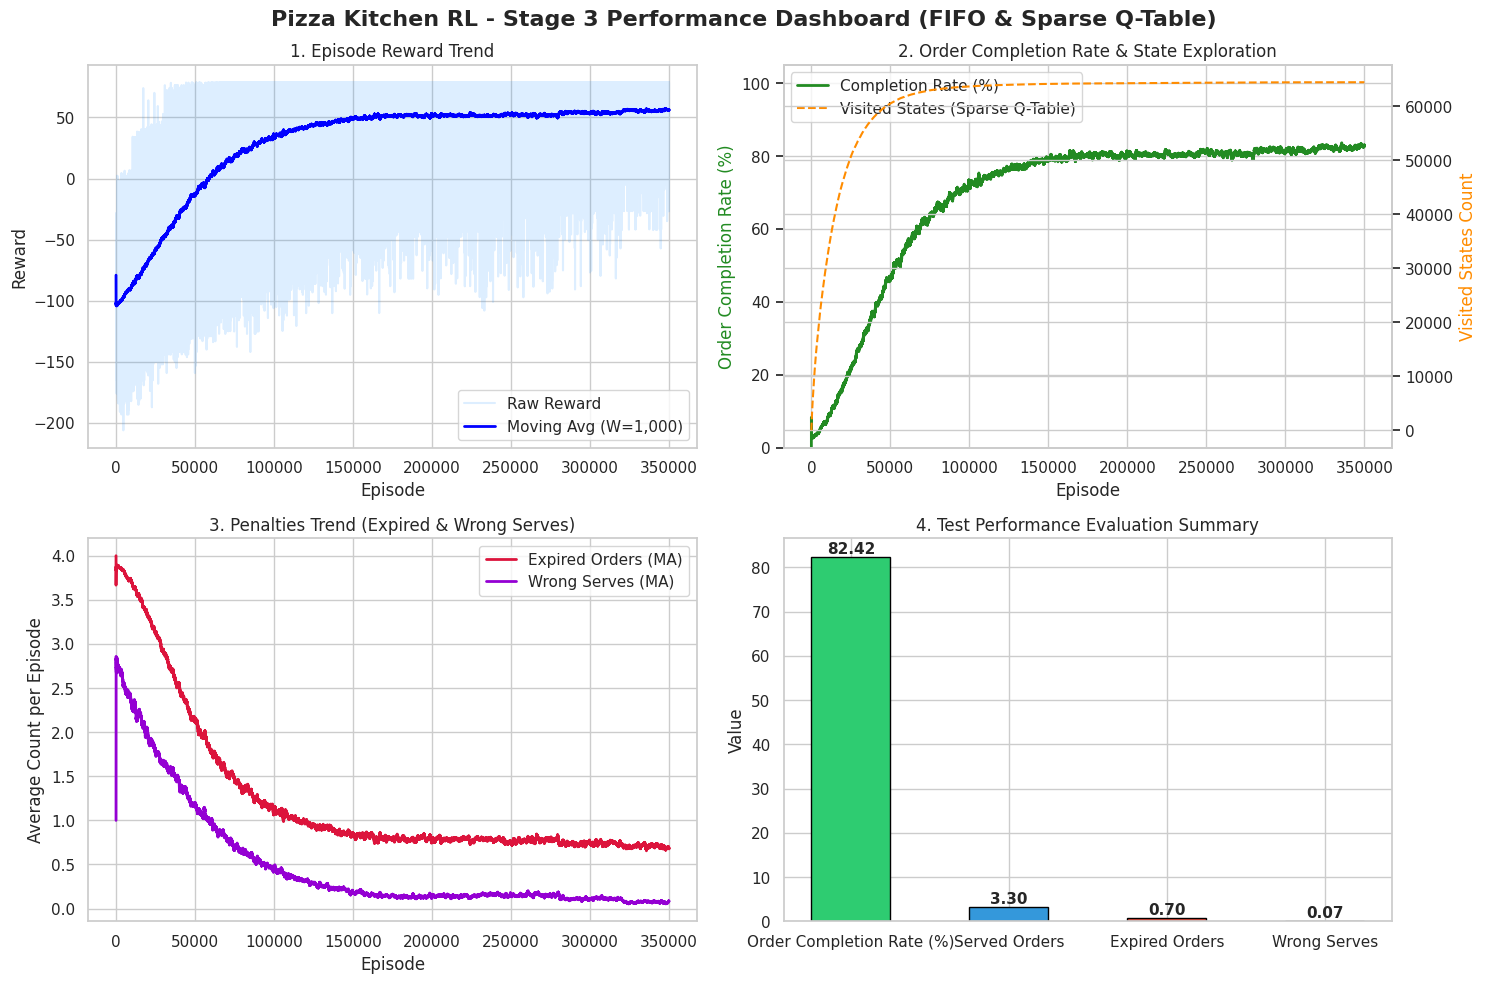

In [17]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. 스타일 및 한글/글꼴 설정
sns.set_theme(style="whitegrid")
plt.rcParams["font.size"] = 11

# 2. 결과 파일 경로 설정 (Stage 3 경로)
output_dir = Path("/content/drive/MyDrive/pizza_rl_lab/results_stage3_final")
history_path = output_dir / "q_learning_history_stage3.csv"
performance_path = output_dir / "performance_summary_stage3.csv"

# 3. 파일 존재 여부 확인 및 데이터 로드
if not history_path.exists():
    raise FileNotFoundError(f"학습 기록 파일이 존재하지 않습니다: {history_path}")

history_df = pd.read_csv(history_path)

# 4. 데이터 전처리 (이동 평균 계산)
WINDOW = 1000  # 이동 평균 구간 (에피소드 수)
n_orders = 4   # Stage 3 주문 수 (4개)

# 이동 평균 열 생성
history_df["reward_ma"] = history_df["reward"].rolling(window=WINDOW, min_periods=1).mean()
history_df["served_ma"] = history_df["served"].rolling(window=WINDOW, min_periods=1).mean()
history_df["completion_rate_ma"] = (history_df["served_ma"] / n_orders) * 100

history_df["expired_ma"] = history_df["expired"].rolling(window=WINDOW, min_periods=1).mean()
history_df["wrong_serves_ma"] = history_df["wrong_serves"].rolling(window=WINDOW, min_periods=1).mean()

# 5. 2x2 시각화 대시보드 생성
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle(
    "Pizza Kitchen RL - Stage 3 Performance Dashboard (FIFO & Sparse Q-Table)",
    fontsize=16,
    fontweight="bold",
)

# [Graph 1] Episode Reward Trend
axes[0, 0].plot(
    history_df["episode"],
    history_df["reward"],
    alpha=0.15,
    color="dodgerblue",
    label="Raw Reward",
)
axes[0, 0].plot(
    history_df["episode"],
    history_df["reward_ma"],
    color="blue",
    linewidth=2,
    label=f"Moving Avg (W={WINDOW:,})",
)
axes[0, 0].set_title("1. Episode Reward Trend")
axes[0, 0].set_xlabel("Episode")
axes[0, 0].set_ylabel("Reward")
axes[0, 0].legend(loc="lower right")

# [Graph 2] Completion Rate (%) & Visited States Count (Dual Y-Axis)
ax2_twin = axes[0, 1].twinx()
p1 = axes[0, 1].plot(
    history_df["episode"],
    history_df["completion_rate_ma"],
    color="forestgreen",
    linewidth=2,
    label="Completion Rate (%)",
)
p2 = ax2_twin.plot(
    history_df["episode"],
    history_df["visited_states"],
    color="darkorange",
    linewidth=1.5,
    linestyle="--",
    label="Visited States (Sparse Q-Table)",
)

axes[0, 1].set_title("2. Order Completion Rate & State Exploration")
axes[0, 1].set_xlabel("Episode")
axes[0, 1].set_ylabel("Order Completion Rate (%)", color="forestgreen")
ax2_twin.set_ylabel("Visited States Count", color="darkorange")
axes[0, 1].set_ylim(0, 105)

# 범례 통합
lines = p1 + p2
labels = [l.get_label() for l in lines]
axes[0, 1].legend(lines, labels, loc="upper left")

# [Graph 3] Penalties Trend (Expired & Wrong Serves)
axes[1, 0].plot(
    history_df["episode"],
    history_df["expired_ma"],
    color="crimson",
    linewidth=2,
    label="Expired Orders (MA)",
)
axes[1, 0].plot(
    history_df["episode"],
    history_df["wrong_serves_ma"],
    color="darkviolet",
    linewidth=2,
    label="Wrong Serves (MA)",
)
axes[1, 0].set_title("3. Penalties Trend (Expired & Wrong Serves)")
axes[1, 0].set_xlabel("Episode")
axes[1, 0].set_ylabel("Average Count per Episode")
axes[1, 0].legend(loc="upper right")

# [Graph 4] Final Evaluation Summary (Performance Metrics Bar Chart)
if performance_path.exists():
    df_perf = pd.read_csv(performance_path, header=None, names=["Metric", "Value"])

    # 딕셔너리로 변환하여 원하는 지표만 추출
    perf_dict = {}
    for _, row in df_perf.iterrows():
        try:
            # 수치형 변환 시도 (문자열 포맷 제거)
            val_str = str(row["Value"]).replace("%", "").split("/")[0].strip()
            perf_dict[row["Metric"]] = float(val_str)
        except ValueError:
            continue

    metrics_to_plot = [
        "Order Completion Rate (%)",
        "Average Served Orders (Max 4)",
        "Average Expired Orders",
        "Average Wrong Serves",
    ]

    # 존재하는 지표만 필터링
    plot_labels = []
    plot_values = []
    for m in metrics_to_plot:
        if m in perf_dict:
            plot_labels.append(m.replace("Average ", "").replace(" (Max 4)", ""))
            plot_values.append(perf_dict[m])

    colors = ["#2ecc71", "#3498db", "#e74c3c", "#9b59b6"]
    bars = axes[1, 1].bar(
        plot_labels, plot_values, color=colors[:len(plot_values)], width=0.5, edgecolor="black"
    )
    axes[1, 1].set_title("4. Test Performance Evaluation Summary")
    axes[1, 1].set_ylabel("Value")

    # 막대 그래프 위 값 명시
    for bar in bars:
        yval = bar.get_height()
        axes[1, 1].text(
            bar.get_x() + bar.get_width() / 2,
            yval + (0.05 if yval >= 0 else -0.1),
            f"{yval:.2f}",
            ha="center",
            va="bottom",
            fontweight="bold",
        )
else:
    axes[1, 1].text(
        0.5, 0.5, "Performance Summary File Not Found", ha="center", va="center", fontsize=12
    )
    axes[1, 1].set_title("4. Test Performance Summary")

plt.tight_layout()

# 6. 이미지 저장 및 출력
save_fig_path = output_dir / "performance_dashboard_stage3.png"
plt.savefig(save_fig_path, dpi=300)
print(f" Stage 3 시각화 대시보드가 성공적으로 저장되었습니다:\n- {save_fig_path}")

plt.show()